In [1]:
# Day 21: Student Performance Prediction System
# Topic: Student Performance Classification and Risk Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 55)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 21 - STUDENT PERFORMANCE CLASSIFICATION")
print("=" * 55)

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 21 - STUDENT PERFORMANCE CLASSIFICATION


In [2]:
# Step 2: Create Student Dataset

data = {
    "Study_Hours": [2, 3, 4, 5, 6, 1, 7, 8, 3, 5, 6, 2, 9, 4, 7],
    "Attendance": [60, 70, 75, 80, 85, 50, 90, 95, 65, 78, 88, 55, 98, 72, 92],
    "Previous_Marks": [45, 50, 55, 60, 65, 35, 75, 85, 48, 62, 70, 40, 90, 58, 80],
    "Final_Marks": [48, 52, 58, 65, 70, 38, 78, 88, 50, 64, 73, 42, 94, 60, 83]
}

df = pd.DataFrame(data)

print("Student Dataset:")
display(df)

print("\nDataset Shape:", df.shape)

Student Dataset:


,Study_Hours,Attendance,Previous_Marks,Final_Marks
0,2,60,45,48
1,3,70,50,52
2,4,75,55,58
3,5,80,60,65
4,6,85,65,70
5,1,50,35,38
6,7,90,75,78
7,8,95,85,88
8,3,65,48,50
9,5,78,62,64



Dataset Shape: (15, 4)


In [3]:
# Step 3: Classify Student Performance

def classify_performance(marks):
    if marks < 50:
        return "Needs Support"
    elif marks < 75:
        return "Average"
    else:
        return "Good"

df["Performance_Category"] = df["Final_Marks"].apply(
    classify_performance
)

print("Student Performance Classification:")
display(df[["Final_Marks", "Performance_Category"]])

print("\nCategory Counts:")
print(df["Performance_Category"].value_counts())

Student Performance Classification:


,Final_Marks,Performance_Category
0,48,Needs Support
1,52,Average
2,58,Average
3,65,Average
4,70,Average
5,38,Needs Support
6,78,Good
7,88,Good
8,50,Average
9,64,Average



Category Counts:
Performance_Category
Average          8
Good             4
Needs Support    3
Name: count, dtype: int64


In [4]:
# Step 4: Prepare Features and Target

X = df[["Study_Hours", "Attendance", "Previous_Marks"]]

y = df["Performance_Category"]

print("Input Features (X):")
display(X.head())

print("\nTarget Variable (y):")
display(y.head())

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features (X):


,Study_Hours,Attendance,Previous_Marks
0,2,60,45
1,3,70,50
2,4,75,55
3,5,80,60
4,6,85,65



Target Variable (y):


0    Needs Support
1          Average
2          Average
3          Average
4          Average
Name: Performance_Category, dtype: str


Features Shape: (15, 3)
Target Shape: (15,)


In [5]:
# Step 5: Split Training and Testing Data

np.random.seed(42)

indices = np.random.permutation(len(X))

test_size = 3
test_indices = indices[:test_size]
train_indices = indices[test_size:]

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Data Shape: (12, 3)
Testing Data Shape: (3, 3)

Training Samples: 12
Testing Samples: 3


In [6]:
# Step 6: Train KNN Classification Model

# Standardize features using training data only
X_train_mean = X_train.mean()
X_train_std = X_train.std().replace(0, 1)

X_train_scaled = (X_train - X_train_mean) / X_train_std
X_test_scaled = (X_test - X_train_mean) / X_train_std

# KNN with 3 nearest neighbors
k = 3
predictions = []

for test_row in X_test_scaled.to_numpy():
    distances = np.sqrt(
        np.sum((X_train_scaled.to_numpy() - test_row) ** 2, axis=1)
    )

    nearest_indices = np.argsort(distances)[:k]
    nearest_labels = y_train.iloc[nearest_indices]

    predicted_category = nearest_labels.mode().iloc[0]
    predictions.append(predicted_category)

y_pred = np.array(predictions)

print("KNN Classification Completed Successfully!")
print("Number of Neighbors (k):", k)
print("Predicted Categories:", y_pred)

KNN Classification Completed Successfully!
Number of Neighbors (k): 3
Predicted Categories: ['Average' 'Average' 'Average']


In [7]:
# Step 7: Compare Actual and Predicted Categories

results = pd.DataFrame({
    "Actual_Category": y_test.to_numpy(),
    "Predicted_Category": y_pred
})

results["Correct_Prediction"] = (
    results["Actual_Category"] == results["Predicted_Category"]
)

print("Student Performance Classification Results:")
display(results)

print("\nCorrect Predictions:", results["Correct_Prediction"].sum())
print("Total Test Students:", len(results))

Student Performance Classification Results:


,Actual_Category,Predicted_Category,Correct_Prediction
0,Average,Average,True
1,Needs Support,Average,False
2,Needs Support,Average,False



Correct Predictions: 1
Total Test Students: 3


In [8]:
# Step 8: Calculate Model Accuracy

correct_predictions = (
    results["Actual_Category"] == results["Predicted_Category"]
).sum()

total_predictions = len(results)

accuracy = (correct_predictions / total_predictions) * 100

print("=" * 40)
print("MODEL EVALUATION RESULTS")
print("=" * 40)

print("Correct Predictions:", correct_predictions)
print("Total Test Students:", total_predictions)
print(f"Classification Accuracy: {accuracy:.2f}%")

MODEL EVALUATION RESULTS
Correct Predictions: 1
Total Test Students: 3
Classification Accuracy: 33.33%


In [9]:
# Step 9: Create Confusion Matrix

confusion_matrix = pd.crosstab(
    results["Actual_Category"],
    results["Predicted_Category"],
    rownames=["Actual"],
    colnames=["Predicted"],
    dropna=False
)

print("CONFUSION MATRIX")
display(confusion_matrix)

CONFUSION MATRIX


Predicted,Average
Actual,
Average,1
Needs Support,2


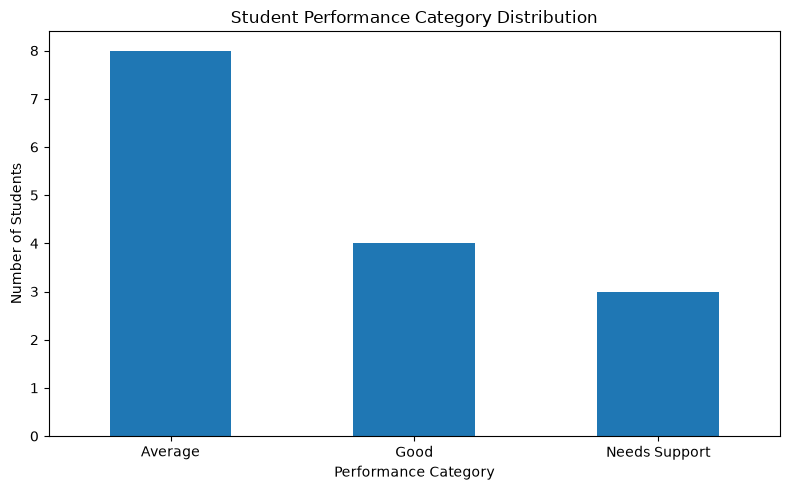

Student Performance Category Counts:
Performance_Category
Average          8
Good             4
Needs Support    3
Name: count, dtype: int64


In [10]:
# Step 10: Visualize Student Performance Categories

category_counts = df["Performance_Category"].value_counts()

plt.figure(figsize=(8, 5))
category_counts.plot(kind="bar")

plt.title("Student Performance Category Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Student Performance Category Counts:")
print(category_counts)


In [11]:
# Step 11: Predict Performance for a New Student

new_student = pd.DataFrame({
"Study_Hours": [5],
"Attendance": [82],
"Previous_Marks": [68]
})

# Apply the same scaling used for training data

new_student_scaled = (
new_student - X_train_mean
) / X_train_std

# Calculate distances from training students

distances = np.sqrt(
np.sum(
(X_train_scaled.to_numpy() - new_student_scaled.to_numpy()[0]) ** 2,
axis=1
)
)

# Find the 3 nearest neighbors

nearest_indices = np.argsort(distances)[:k]
nearest_labels = y_train.iloc[nearest_indices]

# Predict using majority vote

predicted_category = nearest_labels.mode().iloc[0]

print("NEW STUDENT DETAILS")
display(new_student)

print("Predicted Performance Category:", predicted_category)
print("Nearest Neighbor Categories:")
print(nearest_labels.to_list())


NEW STUDENT DETAILS


,Study_Hours,Attendance,Previous_Marks
0,5,82,68


Predicted Performance Category: Average
Nearest Neighbor Categories:
['Average', 'Average', 'Average']


In [12]:
# Step 12: Save Student Performance Classification Report

report = df.copy()

report["Model_Predicted_Category"] = "Not Tested"
report["Correct_Prediction"] = pd.NA

# Add predictions for test students

report.loc[y_test.index, "Model_Predicted_Category"] = y_pred

report.loc[y_test.index, "Correct_Prediction"] = (
y_test.to_numpy() == y_pred
)

# Save report to CSV

report_path = "day21_student_performance_classification_report.csv"
report.to_csv(report_path, index=False)

print("Classification Report Saved Successfully!")
print("File Name:", report_path)

display(report)


Classification Report Saved Successfully!
File Name: day21_student_performance_classification_report.csv


,Study_Hours,Attendance,Previous_Marks,Final_Marks,Performance_Category,Model_Predicted_Category,Correct_Prediction
0,2,60,45,48,Needs Support,Average,False
1,3,70,50,52,Average,Not Tested,<NA>
2,4,75,55,58,Average,Not Tested,<NA>
3,5,80,60,65,Average,Not Tested,<NA>
4,6,85,65,70,Average,Not Tested,<NA>
5,1,50,35,38,Needs Support,Not Tested,<NA>
6,7,90,75,78,Good,Not Tested,<NA>
7,8,95,85,88,Good,Not Tested,<NA>
8,3,65,48,50,Average,Not Tested,<NA>
9,5,78,62,64,Average,Average,True
